# Lab 2: Discovery of Frequent Itemsets and Association

In this laboratory work I explore the concept of `frequent itemsets` and build the pipeline for detecting them in a dataset and then generating `association rules`. I decided to use Spark as the main framework for building the pipeline.

## Setup

First install all of the required dependencies.

In [2]:
!sudo apt-get update -qq
!sudo apt-get install -y -qq --no-install-recommends openjdk-17-jre-headless
%pip install -q pyspark sympy matplotlib

Note: you may need to restart the kernel to use updated packages.


Next up, create the instance of Spark and configure it with basic parameters.

In [3]:
import os, sys, subprocess
os.environ["PYSPARK_PYTHON"] = sys.executable

print(subprocess.run(["java", "-version"], capture_output=True, text=True).stderr)

from pyspark.sql import SparkSession

spark = (SparkSession.builder
         .appName("lab1")
         .master("local[*]")
         .config("spark.driver.memory", "4g")
         .config("spark.sql.shuffle.partitions", "8")
         .config("spark.network.timeout", "600s")
         .config("spark.executor.heartbeatInterval", "60s")
         .getOrCreate())

sc = spark.sparkContext

print(spark.version)

openjdk version "17.0.21.0.3" 2026-10-24
OpenJDK Runtime Environment (build 17.0.21.0.3+1-1-26.04.1-Ubuntu)
OpenJDK 64-Bit Server VM (build 17.0.21.0.3+1-1-26.04.1-Ubuntu, mixed mode, sharing)



Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/11/18 14:29:59 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


4.3.0


The dataset for this laboratory work was provided in the assignment and represents a synthetic dataset called `T10I4D100K`. It consists of a single `.dat` file which contains a set of rows `(baskets)` with the ids of their `items`. In order to use the dataset in this notebook store it in the following way relatively to the notebook's path. `..datasets/transactions.dat`.

In [5]:
with open("../datasets/transactions.dat", "rb") as f:
    chunk = f.read(300)

print(chunk)

b'25 52 164 240 274 328 368 448 538 561 630 687 730 775 825 834 \n39 120 124 205 401 581 704 814 825 834 \n35 249 674 712 733 759 854 950 \n39 422 449 704 825 857 895 937 954 964 \n15 229 262 283 294 352 381 708 738 766 853 883 966 978 \n26 104 143 320 569 620 798 \n7 185 214 350 529 658 682 782 809 849 883'


## Finding frequent itemsets

Before starting to search for the frequent itemsets transform the dataset into suitable format - each non-empty line should represent a sorted set of integer product ids.

In [4]:
baskets = (sc.textFile("../datasets/transactions.dat")
            .map(lambda line: tuple(sorted(set(map(int, line.split())))))
            .filter(len)
            .cache())

print(baskets.count())

[Stage 0:>                                                          (0 + 2) / 2]

100000


In order to identify frequent itemsets with above a certain `support` threshold (the fraction of the baskets which contain the itemset) the `Apriori` algorithm is used. It needs `k` passes over the data: the first pass counts the number of occurences of each individual item and selects frequent items; the consequent passes construct the itemsets of size `k` by using the frequent sets from step `k - 1` and frequent singletons.

In [5]:
from itertools import combinations
from operator import add

class Apriori:
    def __init__(self, support: float):
        self.s = support

    def find_frequent_itemsets(self, baskets_rdd) -> dict[int, dict[tuple, int]]:
        sc = baskets_rdd.context
        min_count = self.s * baskets_rdd.count()
        result = {}

        singles = (baskets_rdd.flatMap(lambda b: b)
                              .map(lambda x: ((x,), 1))
                              .reduceByKey(add)
                              .filter(lambda kv: kv[1] >= min_count)
                              .collectAsMap())
        result[1] = singles

        frequent_items = sorted(t[0] for t in singles)

        k = 2

        while result[k - 1]:
            candidates = self._generate_candidates(set(result[k - 1]), frequent_items, k)

            if not candidates:
                break

            bc = sc.broadcast(candidates)

            counts = (baskets_rdd
                      .flatMap(lambda b: [(c, 1) for c in combinations(b, k) if c in bc.value])
                      .reduceByKey(add)
                      .filter(lambda kv: kv[1] >= min_count)
                      .collectAsMap())

            bc.unpersist()

            if not counts:
                break

            result[k] = counts
            k += 1

        return result

    def _generate_candidates(self, prev_frequent: set[tuple], frequent_items: list[int], k: int) -> set[tuple]:
        candidates = set()

        for itemset in prev_frequent:
            last = itemset[-1]

            for x in frequent_items:
                if x <= last:
                    continue

                candidate = itemset + (x,)

                if all(sub in prev_frequent for sub in combinations(candidate, k - 1)):
                    candidates.add(candidate)

        return candidates

The output of the algorithm is the dictionary with keys equal to the sizes of the itemsets found and values are the itemsets with their count.

In [8]:
apriori = Apriori(support=0.01)

levels = apriori.find_frequent_itemsets(baskets)
print(levels[3])

[Stage 6:>                                                          (0 + 2) / 2]

{(39, 704, 825): 1035}


## Generating association rules

When the `frequent itemsets` are already identified it is possible to generate `association rules` from them (for example, itemset A, B, C may produce the rule A, B -> C) with a certain `confidence` threshold (in the language of statistics it is the probability that given the the left hand side of the rule the union of both sides of the rule is valid). The algorithm for rule generation uses `Apriori` logic and prunes or skips generation of rules which antecedents are the subsets of those antecedents from the rules below confidence threshold (for example, if rule A, B, C -> D is below the threshold then rule A, B -> C, D will not be generated).

In [6]:
class AprioriRules(Apriori):
    def __init__(self, support: float, confidence: float):
        super().__init__(support)
        self.c = confidence

    def generate_association_rules(self, levels: dict[int, dict[tuple, int]]) -> list[tuple[tuple, tuple, float]]:
        counts = {}
        
        for level in levels.values():
            counts.update(level)

        rules = []
        
        for k, itemsets in levels.items():
            if k < 2:
                continue
                
            for itemset, count in itemsets.items():
                rules.extend(self._rules_for_itemset(itemset, count, counts))
        
        return rules

    def _rules_for_itemset(self, itemset: tuple, itemset_count: int, counts: dict) -> list:
        rules = []
        consequents = [(item,) for item in itemset]
        
        m = 1

        while consequents and m < len(itemset):
            surviving = []

            for cons in consequents:
                antecedent = tuple(x for x in itemset if x not in cons)
                confidence = itemset_count / counts[antecedent]

                if confidence >= self.c:
                    surviving.append(cons)
                    rules.append((antecedent, cons, confidence))

            m += 1
            consequents = self._generate_candidates(set(surviving), sorted(itemset), m)

        return rules

The result is the list of the rules with their antecedent, consequent and calculated confidence.

In [9]:
apriori_rules = AprioriRules(support=0.01, confidence=0.6)

levels = apriori.find_frequent_itemsets(baskets)
print(levels[2])

rules = apriori_rules.generate_association_rules(levels)
print(rules)

[Stage 13:>                                                         (0 + 2) / 2]

{(39, 825): 1187, (789, 829): 1194, (368, 682): 1193, (390, 722): 1042, (39, 704): 1107, (704, 825): 1102, (227, 390): 1049, (368, 829): 1194, (217, 346): 1336}
[((704,), (39,), 0.617056856187291), ((704,), (825,), 0.6142697881828316), ((704, 825), (39,), 0.9392014519056261), ((39, 825), (704,), 0.8719460825610783), ((39, 704), (825,), 0.9349593495934959)]


## Evaluation

In order to evaluate the performance of the pipeline I run three experiments on the dataset. First, the search for frequent itemsets with `support` - 0.01 is run three times on `1000, 10000 and 100000` baskets to see how the execution time depends on the size of the input. Second, the whole dataset is processed with `support` thresholds of `0.02, 0.01, 0.005 and 0.0025` to measure the execution time and the number of frequent itemsets found on each level. Finally, the `association rules` are generated from the itemsets found with each support using `confidence` thresholds from 0.3 to 0.95, and on each run the benchmark records the execution time and the number of generated rules. Besides the confidence, every rule is also described by its `support` and `interest` (the difference between the confidence of the rule and the fraction of the baskets which contain its consequent).

In [7]:
import time
import numpy as np
import matplotlib.pyplot as plt

all_baskets = baskets.collect()
N_ALL = len(all_baskets)

def timed(fn):
    t0 = time.perf_counter()
    out = fn()
    return out, time.perf_counter() - t0

def make_rdd(n):
    rdd = sc.parallelize(all_baskets[:n], numSlices=16).cache()
    rdd.count()
    return rdd

SUPPORT, RUNS = 0.01, 3
sizes = [1_000, 10_000, 100_000]

r = make_rdd(1_000)
Apriori(SUPPORT).find_frequent_itemsets(r)
r.unpersist()

scal = {}

for n in sizes:
    rdd = make_rdd(n)
    ts = [timed(lambda: Apriori(SUPPORT).find_frequent_itemsets(rdd))[1] for _ in range(RUNS)]
    scal[n] = sorted(ts)[RUNS // 2] 
    rdd.unpersist()
    print(n, round(scal[n], 2), "s")

supports = [0.02, 0.01, 0.005, 0.0025]
rdd = make_rdd(N_ALL)
sweep, levels_by_s = {}, {}

for s in supports:
    levels, t = timed(lambda: Apriori(s).find_frequent_itemsets(rdd))
    levels_by_s[s] = levels
    sweep[s] = {"time": t,
                "per_level": {k: len(v) for k, v in levels.items()},
                "total": sum(len(v) for v in levels.values())}
    print(s, round(t, 1), "s", sweep[s]["per_level"])

1000 1.64 s
10000 1.1 s


100000 1.74 s
0.02 0.7 s {1: 155}


0.01 1.7 s {1: 375, 2: 9, 3: 1}


0.005 8.5 s {1: 569, 2: 342, 3: 110, 4: 43, 5: 9}


[Stage 133:===================================================>   (15 + 1) / 16]

0.0025 25.3 s {1: 717, 2: 2661, 3: 2014, 4: 1315, 5: 667, 6: 253, 7: 66, 8: 10}


In [8]:
S_RULES, C_RULES = 0.005, 0.5
levels = levels_by_s[S_RULES]

rules = AprioriRules(S_RULES, C_RULES).generate_association_rules(levels)

counts = {}

for lv in levels.values():
    counts.update(lv)

rows = []

for lhs, rhs, conf in rules:
    rows.append(dict(
        lhs=lhs, rhs=rhs,
        support=counts[tuple(sorted(lhs + rhs))] / N_ALL,
        confidence=conf,
        interest=conf - counts[rhs] / N_ALL,
    ))

print(len(rows), "rules")

for r in sorted(rows, key=lambda r: -r["interest"])[:10]:
    print(r["lhs"], "->", r["rhs"],
          f"supp={r['support']:.4f}  conf={r['confidence']:.2f}  interest={r['interest']:.2f}")

1145 rules
(185, 471, 960) -> (678,) supp=0.0065  conf=0.99  interest=0.97
(217, 661, 923, 947) -> (546,) supp=0.0056  conf=0.98  interest=0.97
(217, 661, 947) -> (546,) supp=0.0057  conf=0.98  interest=0.97
(471, 678, 960) -> (185,) supp=0.0065  conf=0.98  interest=0.97
(661, 923, 947) -> (546,) supp=0.0058  conf=0.98  interest=0.97
(217, 661, 923) -> (546,) supp=0.0057  conf=0.98  interest=0.97
(185, 678) -> (471, 960) supp=0.0065  conf=0.98  interest=0.97
(185, 678, 960) -> (471,) supp=0.0065  conf=0.99  interest=0.96
(217, 546, 947) -> (661,) supp=0.0057  conf=0.99  interest=0.96
(217, 546, 923) -> (661,) supp=0.0057  conf=0.99  interest=0.96


In [9]:
CONFIDENCES = [0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 0.95]
rule_supports = [s for s in supports if len(levels_by_s[s]) > 1]
conf_sweep = {}

for s in rule_supports:
    conf_sweep[s] = {}

    for c in CONFIDENCES:
        runs = [timed(lambda: AprioriRules(s, c).generate_association_rules(levels_by_s[s])) for _ in range(RUNS)]
        conf_sweep[s][c] = {"time": sorted(t for _, t in runs)[RUNS // 2],
                            "rules": len(runs[0][0])}

    print(s, {c: (round(v["time"] * 1000, 1), v["rules"]) for c, v in conf_sweep[s].items()})

0.01 {0.3: (0.1, 13), 0.4: (0.0, 7), 0.5: (0.0, 7), 0.6: (0.0, 5), 0.7: (0.0, 3), 0.8: (0.0, 3), 0.9: (0.0, 2), 0.95: (0.0, 0)}
0.005 {0.3: (3.0, 1391), 0.4: (3.0, 1265), 0.5: (2.1, 1145), 0.6: (2.1, 1072), 0.7: (2.0, 995), 0.8: (2.0, 924), 0.9: (1.4, 532), 0.95: (1.0, 176)}
0.0025 {0.3: (104.0, 65554), 0.4: (102.9, 63281), 0.5: (99.2, 62293), 0.6: (104.5, 60806), 0.7: (92.6, 58944), 0.8: (92.5, 54722), 0.9: (69.7, 36807), 0.95: (39.0, 14943)}


The results show that the execution time of the search for frequent itemsets barely changes with the number of baskets, which means that on this dataset it is dominated by the fixed cost of the Spark jobs started on each pass rather than by the amount of data. On the other hand, lowering the `support` threshold increases the execution time drastically: the number of frequent itemsets grows very fast, new levels of bigger itemsets appear and each of them requires one more pass over the data with more candidates to check. The strongest `association rules` have confidence close to 1 and high interest, which means that some groups of items are almost always bought together. The generation of rules takes only milliseconds, which is negligible compared to the search for frequent itemsets, because it works with the already counted itemsets on the driver and does not need any passes over the data. Both the number of rules and the generation time decrease slowly while the `confidence` threshold grows and drop sharply only for the highest thresholds, so most of the rules found are strong. The time follows the number of rules because the `Apriori` pruning stops expanding the consequents of the rules below the threshold. The graphs below demonstrate how the execution time and the size of the output depend on the size of the input, the support and the confidence thresholds.

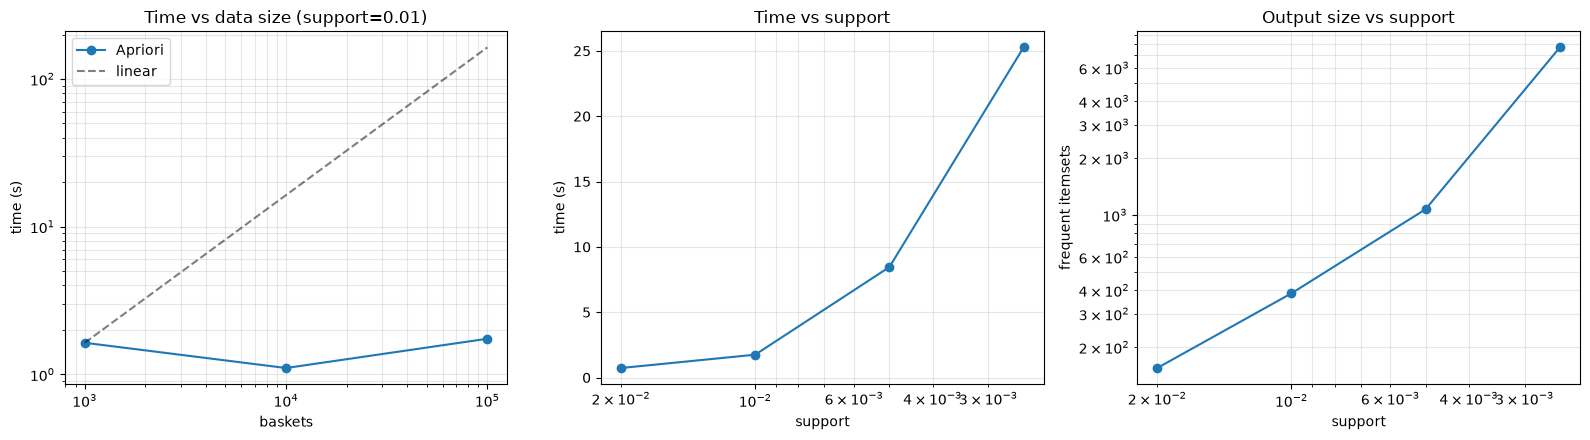

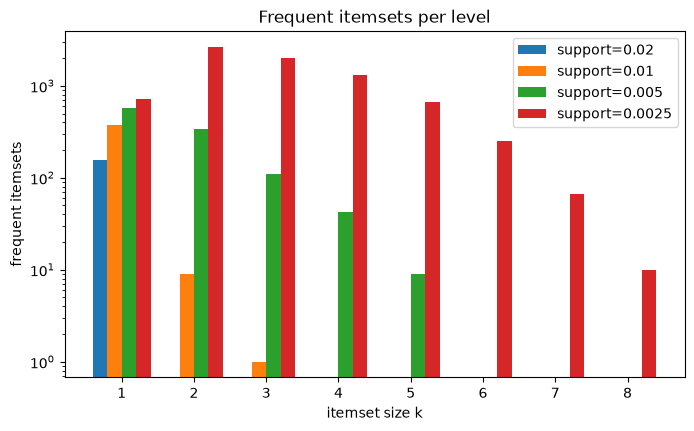

In [10]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))

# 1: time vs data size (log-log, with a linear-scaling reference)
ax[0].loglog(sizes, [scal[n] for n in sizes], "o-", label="Apriori")
ax[0].loglog(sizes, [scal[sizes[0]] * n / sizes[0] for n in sizes], "k--", alpha=.5, label="linear")
ax[0].set(xlabel="baskets", ylabel="time (s)", title=f"Time vs data size (support={SUPPORT})")
ax[0].legend()

# 2: time vs support
ax[1].semilogx(supports, [sweep[s]["time"] for s in supports], "o-")
ax[1].set(xlabel="support", ylabel="time (s)", title="Time vs support")
ax[1].invert_xaxis()

# 3: output size vs support
ax[2].loglog(supports, [sweep[s]["total"] for s in supports], "o-")
ax[2].set(xlabel="support", ylabel="frequent itemsets", title="Output size vs support")
ax[2].invert_xaxis()

for a in ax:
    a.grid(alpha=.3, which="both")
    
plt.tight_layout(); plt.show()

# 4: frequent itemsets per level, one bar group per support
max_k = max(max(sweep[s]["per_level"]) for s in supports)
x, w = np.arange(1, max_k + 1), 0.8 / len(supports)

plt.figure(figsize=(8, 4.5))

for i, s in enumerate(supports):
    plt.bar(x + i * w, [sweep[s]["per_level"].get(k, 0) for k in x], w, label=f"support={s}")
    
plt.yscale("log")
plt.xlabel("itemset size k"); plt.ylabel("frequent itemsets")
plt.xticks(x + 0.4 - w / 2, x)
plt.title("Frequent itemsets per level"); plt.legend(); plt.show()

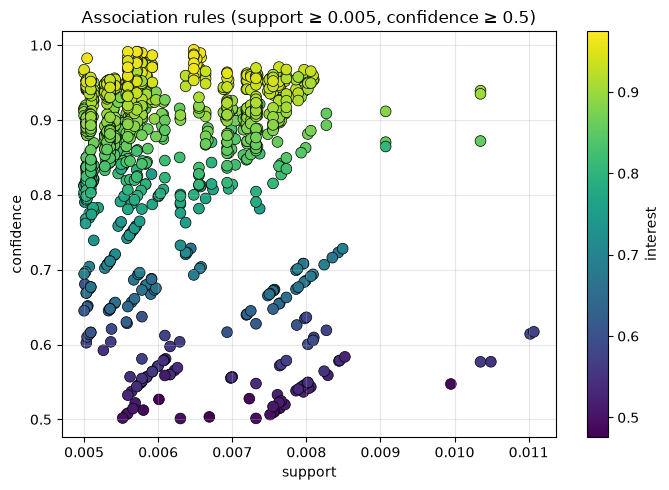

In [11]:
## 5: scatter plot of the association rules' confidence and interest
plt.figure(figsize=(7, 5))

sca = plt.scatter([r["support"] for r in rows],
                  [r["confidence"] for r in rows],
                  c=[r["interest"] for r in rows],
                  cmap="viridis", s=60, edgecolors="k", linewidths=0.5)

plt.colorbar(sca, label="interest")
plt.xlabel("support"); plt.ylabel("confidence")
plt.title(f"Association rules (support ≥ {S_RULES}, confidence ≥ {C_RULES})")
plt.grid(alpha=.3)
plt.tight_layout(); plt.show()

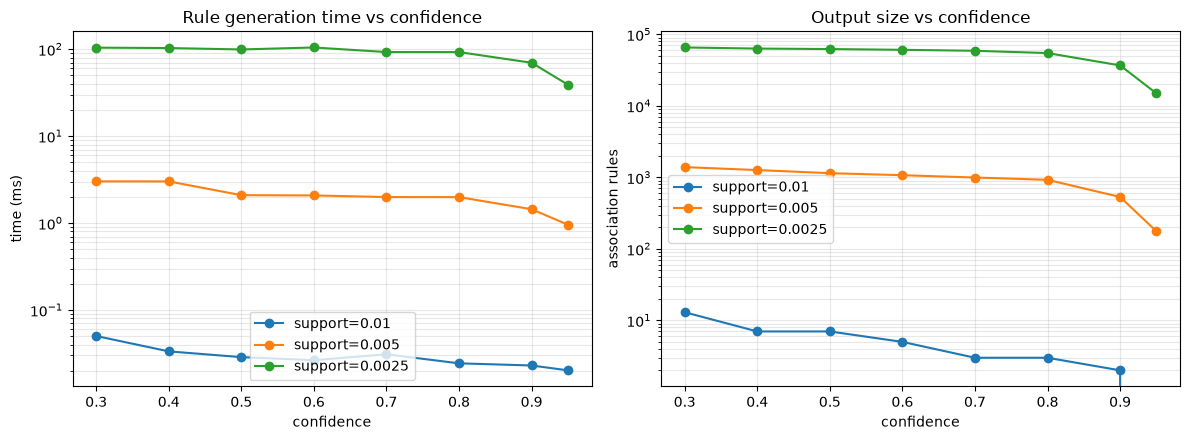

In [12]:
# 6: time and output size vs confidence, one line per support
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))

for s in rule_supports:
    ax[0].semilogy(CONFIDENCES, [conf_sweep[s][c]["time"] * 1000 for c in CONFIDENCES], "o-", label=f"support={s}")
    ax[1].semilogy(CONFIDENCES, [conf_sweep[s][c]["rules"] for c in CONFIDENCES], "o-", label=f"support={s}")

ax[0].set(xlabel="confidence", ylabel="time (ms)", title="Rule generation time vs confidence")
ax[1].set(xlabel="confidence", ylabel="association rules", title="Output size vs confidence")

for a in ax:
    a.grid(alpha=.3, which="both")

fig.legend(*ax[0].get_legend_handles_labels(), loc="lower center", ncol=len(rule_supports))
plt.tight_layout(rect=(0, 0.08, 1, 1)); plt.show()

## Conclusions

The experiments of this laboratory work show that the `Apriori` algorithm is a reliable way to find frequent itemsets and association rules in a large set of baskets. Its execution time stayed almost the same while the number of baskets grew, which shows that on this dataset the cost is defined by the number of passes and candidates rather than by the size of the input. The `support` threshold turned out to be the main parameter: lowering it quickly increases the number of frequent itemsets, adds new levels of bigger itemsets and makes the search much slower, while the generation of rules takes only milliseconds and depends on the `confidence` threshold much less. Confidence alone is not enough to judge a rule, so `interest` was used to show how much the antecedent actually raises the probability of the consequent compared to its overall frequency. Some of the results may seem unusual: most of the rules have confidence and interest close to 1. This is explained by the synthetic nature of `T10I4D100K`, whose baskets are generated from a set of planted patterns, so real shopping data would most likely produce fewer and weaker rules.